## Contexto do Problema

**Dataset**: Telco Customer Churn (Kaggle)
**Origem**: empresa de telecomunicações fictícia, com dados de 7.043 clientes.
**Objetivo de negócio**: prever quais clientes têm risco de cancelar (churn) o serviço,
para que a equipe de retenção possa agir preventivamente com ofertas.

### Dicionário de Dados (colunas usadas)

| Coluna | Tipo | Significado |
|---|---|---|
| tenure | int | Meses de relacionamento com a empresa |
| MonthlyCharges | float | Valor cobrado por mês |
| TotalCharges | float | Valor total já pago pelo cliente |
| Contract | str | Tipo de contrato (Month-to-month, One year, Two year) |
| PaymentMethod | str | Forma de pagamento |
| InternetService | str | Tipo de internet (DSL, Fiber optic, No) |
| TechSupport | str | Possui suporte técnico? (Yes/No/No internet service) |
| OnlineSecurity | str | Possui segurança online? (Yes/No/No internet service) |
| **Churn** | str | **Target**: Yes = cancelou, No = permaneceu |

In [5]:
## Imports e carga dos dados

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../WA_Fn-UseC_-Telco-Customer-Churn.csv")
print("Shape:", df.shape)
df.head()

Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [6]:
## Tratamento de nulos (CRÍTICO para este dataset)

# 1) TotalCharges vem como string com espaços → converter para numérico
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

# 2) Ver quantos nulos ficaram
print("Nulos por coluna:")
print(df.isnull().sum()[df.isnull().sum() > 0])

# 3) Remover as linhas com nulo em TotalCharges
#    (são só 11 no dataset original, não impacta a amostra)
df = df.dropna(subset=["TotalCharges"]).reset_index(drop=True)

# 4) Remover customerID (não é preditivo, é só identificador)
df = df.drop(columns=["customerID"])

print("Shape após limpeza:", df.shape)

Nulos por coluna:
TotalCharges    11
dtype: int64
Shape após limpeza: (7032, 20)


Shape: (7032, 20)

Valores nulos: 0


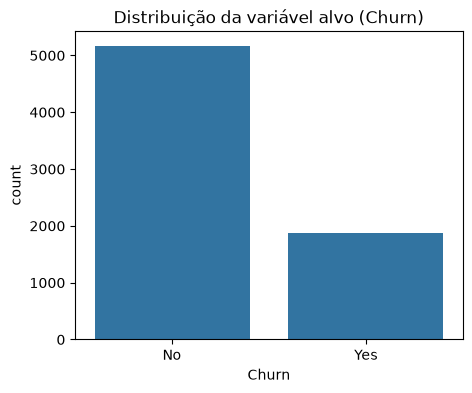

Churn
No     0.734215
Yes    0.265785
Name: proportion, dtype: float64


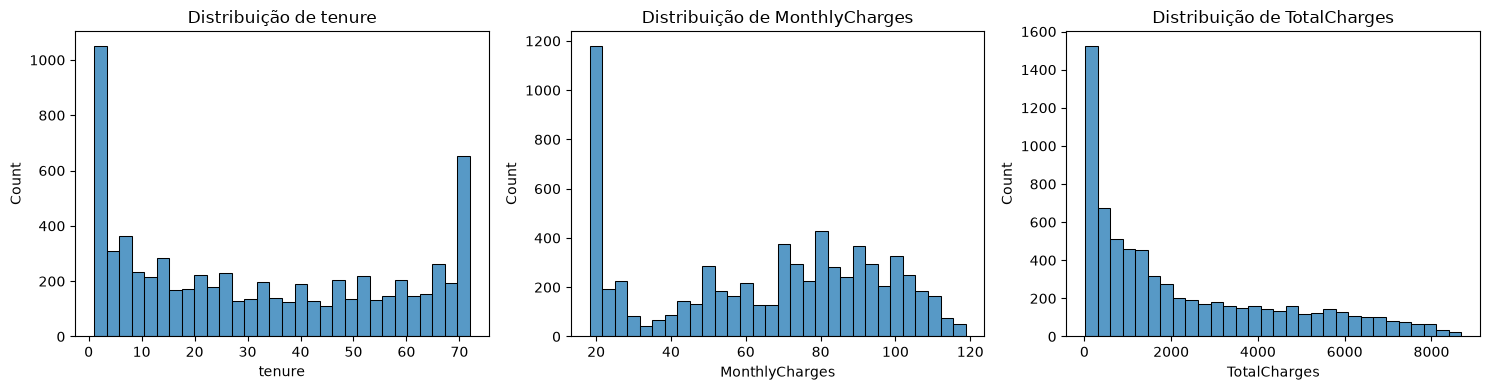

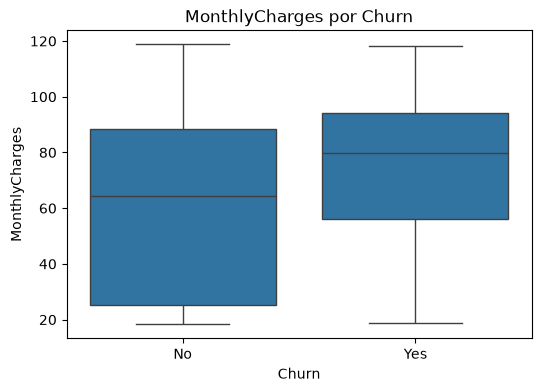

In [7]:
## EDA (análise exploratória)

# Dimensionalidade e nulos (já vimos, mas registra no notebook)
print("Shape:", df.shape)
print("\nValores nulos:", df.isnull().sum().sum())

# Desbalanceamento do target
plt.figure(figsize=(5,4))
sns.countplot(x="Churn", data=df)
plt.title("Distribuição da variável alvo (Churn)")
plt.show()

print(df["Churn"].value_counts(normalize=True))

# Distribuição de features numéricas críticas
fig, axes = plt.subplots(1, 3, figsize=(15,4))
for ax, col in zip(axes, ["tenure", "MonthlyCharges", "TotalCharges"]):
    sns.histplot(df[col], bins=30, ax=ax)
    ax.set_title(f"Distribuição de {col}")
plt.tight_layout()
plt.show()

# Boxplot: MonthlyCharges por Churn (mostra que churn tende a pagar mais)
plt.figure(figsize=(6,4))
sns.boxplot(x="Churn", y="MonthlyCharges", data=df)
plt.title("MonthlyCharges por Churn")
plt.show()

In [8]:
## Separar X e y + train/test split

from sklearn.model_selection import train_test_split

X = df.drop("Churn", axis=1)
y = df["Churn"].map({"No": 0, "Yes": 1})  # target binário 0/1

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y   # mantém proporção de Yes/No no treino e teste
)

print("Treino:", X_train.shape, "| Teste:", X_test.shape)

Treino: (5625, 19) | Teste: (1407, 19)


In [9]:
## Construir o Pipeline

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline

# Identificar colunas numéricas e categóricas automaticamente
num_cols = X_train.select_dtypes(include=["int64", "float64"]).columns.tolist()
cat_cols = X_train.select_dtypes(include=["object"]).columns.tolist()

print("Numéricas:", num_cols)
print("Categóricas:", cat_cols)

# Pré-processamento
preproc = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ]
)

# Pipeline completo
pipeline = Pipeline(steps=[
    ("preproc", preproc),
    ("mlp", MLPClassifier(
        hidden_layer_sizes=(64, 32),   # 2 camadas ocultas (exigido)
        learning_rate_init=0.001,
        max_iter=1000,
        early_stopping=True,           # para evitar overfitting
        random_state=42,
    ))
])

# Treinar
pipeline.fit(X_train, y_train)
print("Modelo treinado!")



C:\Users\Leandro S Sueoka\AppData\Local\Temp\ipykernel_13208\3869519117.py:10: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X_train.select_dtypes(include=["object"]).columns.tolist()


Numéricas: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Categóricas: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
Modelo treinado!


Acurácia: 0.7868

Classification Report:
              precision    recall  f1-score   support

          No       0.84      0.87      0.86      1033
         Yes       0.61      0.55      0.58       374

    accuracy                           0.79      1407
   macro avg       0.73      0.71      0.72      1407
weighted avg       0.78      0.79      0.78      1407



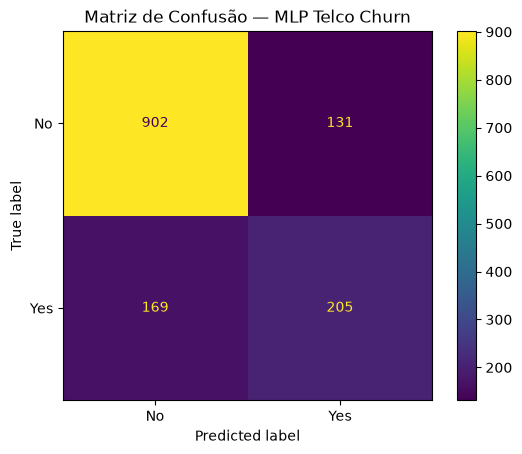

In [10]:
## Avaliação

from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

y_pred = pipeline.predict(X_test)

print(f"Acurácia: {accuracy_score(y_test, y_pred):.4f}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=["No", "Yes"]))

ConfusionMatrixDisplay.from_estimator(pipeline, X_test, y_test, display_labels=["No", "Yes"])
plt.title("Matriz de Confusão — MLP Telco Churn")
plt.show()



In [11]:
## Exportar o modelo

import joblib, os

os.makedirs("../models", exist_ok=True)
joblib.dump(pipeline, "../models/modelo_mlp.joblib")
print("Modelo salvo em ../models/modelo_mlp.joblib")

Modelo salvo em ../models/modelo_mlp.joblib
